In [ ]:
import parquet
import pandas as pd
import pyarrow
import fastparquet
import json 
from pathlib import Path

In [2]:
data_one_baby_id = pd.read_parquet('../vitals/1000600.parquet')

In [3]:
data_one_baby_id.dtypes

site_id                  int32
subject_number_deid      int32
age_us                   int64
HR                     float64
SPO2                   float64
dtype: object

In [3]:
demographic_df = pd.read_parquet('../data/redcap.Demographic and Perinatal data.parquet')

In [4]:
outcome_df = pd.read_parquet('../data/redcap.Discharge & Outcomes data.parquet')

### drawing the missing rate graph

In [46]:
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/analysis/data/results_vectorized_new_data.pkl','rb') as f:
    complete_dict = pd.read_pickle(f)

In [ ]:
final_df = complete_dict['summary_df']
window_sizes_seconds = [int(time/1000000) for time in  complete_dict['window_sizes']]
# the original windoe size in seconds is an int as well

In [31]:
cols = [col for col in final_df.columns if "coverage" in col]
vals = [final_df[col].mean() for col in cols]
hits = [col for col in final_df.columns if "hits" in col]
total_windows = [col for col in final_df.columns if "total_windows" in col]

In [ ]:
# to add columns of hit rate percetnage
for i in range(len(hits)):
    hit_col = hits[i]
    total_windows_col = total_windows[i]
    final_df[ str(window_sizes_seconds[i]) + "s" + " hit rate %"] = final_df[hit_col]/final_df[total_windows_col]

In [ ]:
# to have the hit rate in the weighted form
hit_rate_vals_weighted = []
for i in range(len(hits)):
    hit = hits[i]
    window = total_windows[i]
    hit_rate_vals_weighted.append(final_df[hit].sum()/final_df[window].sum())
    # print(final_df[hit].sum())
    # print(final_df[window].sum())

In [62]:
# to have the hit rate in the average of a percentage form
hit_rate_vals_percentage_cols =  [col for col in final_df.columns if "hit rate %" in col]
hit_rate_vals_percentage = []
for i in range(len(hits)):
    hit_rate_vals_percentage.append(final_df[hit_rate_vals_percentage_cols[i]].mean())

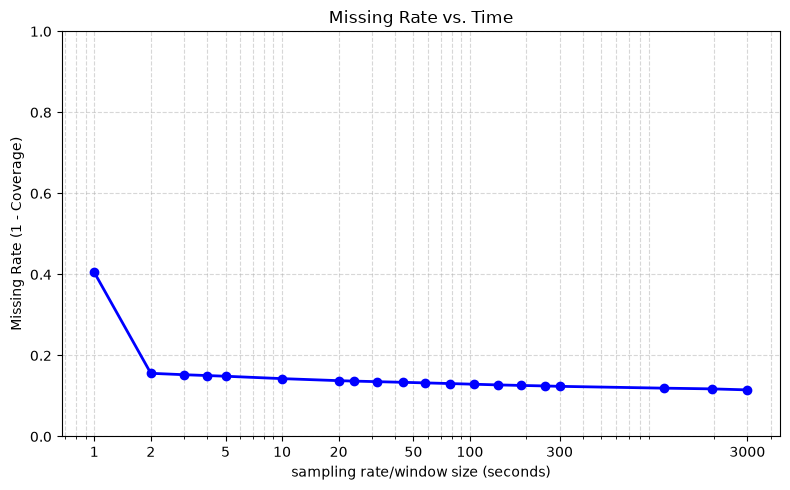

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

# pls ensure the labels are the same as the data in the hitrate scripts
# 1. Raw data
labels = [
    'coverage_1s', 'coverage_2s', 'coverage_3s', 'coverage_4s', 'coverage_5s', 
    'coverage_10s', 'coverage_20s', 'coverage_24s', 'coverage_32s', 'coverage_44s', 
    'coverage_58s', 'coverage_78s', 'coverage_105s', 'coverage_141s', 'coverage_188s', 
    'coverage_252s', 'coverage_300s', "coverage_1083s", "coverage_1940s", 'coverage_3000s'
]


# 2. Extract raw integer second values
seconds = [int(lbl.replace('coverage_', '').replace('s', '')) for lbl in labels]
missing_rates = [1.0 - hr for hr in hit_rate_vals_percentage]

# 3. Create Plot
plt.figure(figsize=(8, 5))
plt.plot(seconds, missing_rates, marker='o', color='b', linestyle='-', linewidth=2)

# Set both axes to log scale
plt.xscale('log')
# plt.yscale('log')
plt.ylim(0,1)

# 4. Force the log-scale axis to display raw numbers instead of 10^x
plt.gca().xaxis.set_major_formatter(ScalarFormatter())
plt.gca().yaxis.set_major_formatter(ScalarFormatter())

# Set custom, clean numeric tick positions so they don't overlap on the log scale
x_ticks = [1, 2, 5, 10, 20, 50, 100, 300, 3000]
plt.xticks(x_ticks, labels=x_ticks)

# NOTE: plt.xlabel(...) is omitted entirely so there is no text label on the X-axis.
plt.ylabel('Missing Rate (1 - Coverage)')
plt.xlabel('sampling rate/window size (seconds)')
plt.title('Missing Rate vs. Time')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig('missing_plot_average_percentage.png', dpi=300, bbox_inches='tight')
plt.show()

### seeing the cols

In [139]:
outcome_cols = list(outcome_df.columns)
demographic_cols = list(demographic_df.columns)
combined_cols = outcome_cols + demographic_cols

In [ ]:
arr = [outcome_df[col].unique() for col in outcome_df.columns]

j=0
for i in arr:
    print(outcome_df.columns[j])
    print(i)
    print("\n")
    j+=1

In [146]:
redcap_metadata = pd.read_parquet('redcap.metadata.parquet')
redcap_metadata = redcap_metadata[['field_name','form_name','field_type','field_label']]
# redcap_metadata = redcap_metadata[redcap_metadata['form_name'].isin(["demographics","discharge_or_death"]) ]
redcap_metadata = redcap_metadata[redcap_metadata['field_name'].isin(combined_cols) ]

In [ ]:
for row in redcap_metadata.iterrows():
    print(row)
    print("\n")

## validating the reported metrics in the paper

In [64]:
demographic_df[demographic_df['vsdata_yn']=="Yes"]['site_id'].value_counts()

site_id
4    1215
2     261
1       1
Name: count, dtype: int64

In [105]:
subject_ids_not_yes = list(demographic_df[demographic_df['vsdata_yn']!="Yes"]['subject_number_deid'])
subject_ids_yes = list(demographic_df[demographic_df['vsdata_yn']=="Yes"]['subject_number_deid'])

In [ ]:
data = str(json.load(open("ro-crate-metadata.json")))
subject_ids_no_in_df_but_yes_in_ro_create = []
for id in subject_ids_not_yes:
    if str(id) in data:
        subject_ids_no_in_df_but_yes_in_ro_create.append(int(id))

In [112]:
data = str(json.load(open("ro-crate-metadata.json")))
subject_ids_yes_in_df_but_no_in_ro_create = []
for id in subject_ids_yes :
    if str(id) not in data:
        subject_ids_yes_in_df_but_no_in_ro_create.append(int(id))

In [129]:
len( subject_ids_yes_in_df_but_no_in_ro_create)

672

In [66]:
refined_df = demographic_df[demographic_df['vsdata_yn']=="Yes"]
refined_df = refined_df[refined_df['site_id']==1]
refined_df

,redcap_event_name,vsdata_yn,demograph_birth_ga_weeks,demograph_birth_ga_days,demograph_gender,demograph_race,presumed_race___1,demograph_ethnicity,dem_adi,multiples,...,eos_organism,eos_abx_days,eos_contaminant,los_num,perinatal_data_complete,site_id,demograph_birthtime_utc_10m,demograph_birth_year,demograph_admit_age_us,subject_number_deid
445,Demographic and Perinatal data,Yes,29.0,6.0,Male,Black or African American,NaN,Non-Hispanic or Non-Latino,45.0,No,...,NaN,NaN,NaN,0.0,Complete,1,17:20:00,2016.0,NaT,1425300


In [62]:
demographic_df['site_id'].value_counts()

site_id
3    2160
1    1623
4    1570
2    1484
Name: count, dtype: int64

In [53]:
outcome_df[outcome_df['died_yn']=="Yes"]['site_id'].value_counts()

site_id
2    274
4    180
3    179
1    171
Name: count, dtype: int64

In [54]:
outcome_df[outcome_df['died_yn']=="No"]['site_id'].value_counts()

site_id
3    1688
1    1379
2    1189
4    1178
Name: count, dtype: int64

## importing the and validating the download of the parquet files

In [156]:
subject_ids = list(demographic_df['subject_number_deid'])
data = str(json.load(open("ro-crate-metadata.json")))
subject_ids_not_in_ro = []
subject_ids_in_ro = []
for id in subject_ids :
    if str(id) in data:
        subject_ids_in_ro.append(int(id))
    else:
        subject_ids_not_in_ro.append(int(id))

In [159]:
demographic_df[demographic_df['subject_number_deid'].isin(subject_ids_in_ro)]['site_id'].value_counts()

site_id
1    1131
3    1073
2     983
4     649
Name: count, dtype: int64

In [165]:
import requests

from pathlib import Path

SERVER = "https://dataverse.lib.virginia.edu"

PID = "doi:10.18130/V3/KCBTMS"

def download_files(name):

    files = requests.get(
        f"{SERVER}/api/datasets/:persistentId/",
        params={"persistentId": PID},
    ).json()["data"]["latestVersion"]["files"]

    Path("downloads").mkdir(exist_ok=True)

    for f in files:
        info = f["dataFile"]
        if name.lower() not in info["filename"].lower():
            continue

        print("Downloading:", info["filename"])

        r = requests.get(
            f"{SERVER}/api/access/datafile/{info['id']}",
            stream=True,
        )

        with open(f"downloads/{info['filename']}", "wb") as out:
            for chunk in r.iter_content(1024 * 1024):
                out.write(chunk)

In [212]:

from concurrent.futures import ThreadPoolExecutor

SERVER = "https://dataverse.lib.virginia.edu"
PID = "doi:10.18130/V3/KCBTMS"

# Get dataset metadata
files = requests.get(
    f"{SERVER}/api/datasets/:persistentId/",
    params={"persistentId": PID},
).json()["data"]["latestVersion"]["files"]

Path("vitals").mkdir(exist_ok=True)


def download(file_info):
    info = file_info["dataFile"]
    print(info)

    r = requests.get(
        f"{SERVER}/api/access/datafile/{info['id']}",
        stream=True,
    )

    with open(f"vitals/{info['filename']}", "wb") as out:
        for chunk in r.iter_content(1024 * 1024):
            out.write(chunk)


# Download all vital parquet files in parallel
with ThreadPoolExecutor(max_workers=16) as executor:
    executor.map(
        download,
        [
            f
            for f in files[:10]
            if f.get("directoryLabel", "").startswith("vitals")
            and f["dataFile"]["filename"].endswith(".parquet")
        ],
    )

print("Done!")

{'id': 118971, 'persistentId': '', 'filename': '1000600.parquet', 'contentType': 'application/octet-stream', 'friendlyType': 'Unknown', 'filesize': 3175594, 'description': '', 'storageIdentifier': 's3://dataverse-storage-production:19d31132289-39dff92451b2', 'rootDataFileId': -1, 'md5': 'ed920058f4e1eaa7c8f5aa061fd38161', 'checksum': {'type': 'MD5', 'value': 'ed920058f4e1eaa7c8f5aa061fd38161'}, 'tabularData': False, 'creationDate': '2026-03-27', 'publicationDate': '2026-04-21', 'directoryLabel': 'vitals', 'lastUpdateTime': '2026-04-21T18:29:41Z', 'fileAccessRequest': True}{'id': 120073, 'persistentId': '', 'filename': '1002700.parquet', 'contentType': 'application/octet-stream', 'friendlyType': 'Unknown', 'filesize': 2053628, 'description': '', 'storageIdentifier': 's3://dataverse-storage-production:19d311322ba-5a8a0bfa1c7f', 'rootDataFileId': -1, 'md5': '5363aee061506e5f34a7ac83a9b7c7a2', 'checksum': {'type': 'MD5', 'value': '5363aee061506e5f34a7ac83a9b7c7a2'}, 'tabularData': False, '

In [ ]:
# f"{SERVER}/api/access/datafile/1425300"
f"{SERVER}/api/access/datafile/1274400"

In [ ]:
id_to_file = {f["dataFile"]["id"]: f["dataFile"] for f in files}
filename_to_file = {f["dataFile"]["filename"]: f["dataFile"] for f in files}

None
{'id': 117851, 'persistentId': '', 'filename': '1006300.parquet', 'contentType': 'application/octet-stream', 'friendlyType': 'Unknown', 'filesize': 1105560, 'description': '', 'storageIdentifier': 's3://dataverse-storage-production:19d31132736-2e65af4bc38c', 'rootDataFileId': -1, 'md5': '358cc81be6c227cbab7e32e4319536ee', 'checksum': {'type': 'MD5', 'value': '358cc81be6c227cbab7e32e4319536ee'}, 'tabularData': False, 'creationDate': '2026-03-27', 'publicationDate': '2026-04-21', 'directoryLabel': 'vitals', 'lastUpdateTime': '2026-04-21T18:29:41Z', 'fileAccessRequest': True}


In [ ]:
# import requests


# print(id_to_file.get(1425300))
# print(filename_to_file.get("1006300.parquet"))

# info = files[0]["dataFile"]

# r = requests.get(
#     f"{SERVER}/api/access/datafile/117851",
#     stream=True,
# )

# print(r.status_code)
# print(r.headers.get("Content-Length"))
# print(r.headers.get("Content-Type"))


200
1105560
application/octet-stream


In [227]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import pandas as pd

vitals_dir = Path("vitals")
files = sorted(vitals_dir.glob("*.parquet"))

def check_file(file):
    subject_id = file.stem

    try:
        pd.read_parquet(file)
        return None

    except Exception:
        # Retry once
        try:
            pd.read_parquet(file)
            return None
        except Exception as e:
            return {
                "subject_id": subject_id,
                "error_type": type(e).__name__,
                "error": str(e),
            }

failed = []

with ThreadPoolExecutor(max_workers=16) as executor:
    futures = [executor.submit(check_file, f) for f in files]

    for future in as_completed(futures):
        result = future.result()
        if result is not None:
            print(f"Failed: {result['subject_id']} -> {result['error_type']}: {result['error']}")
            failed.append(result)

failed_subjects = [x["subject_id"] for x in failed]

print(f"\nNumber of failed files: {len(failed_subjects)}")
print(failed_subjects)

Failed: 1516100 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1591400 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1612200 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1490200 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1504900 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1489300 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1586700 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1553000 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1569000 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1699700 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1611500 -> ArrowInvalid: Could not open Parquet input source '<Buffer>': Parquet magic bytes not found in footer. Either the file is corrupted or this is not a parquet file.
Failed: 1615900 -> TimeoutError: [Errno 60] Operation timed out
Failed: 1532200 -> ArrowInvalid: Could not open Parquet input source '<Buffer>': Parquet magic bytes not found in 

### analyzing the hit rate of the parquet files

In [ ]:
import os
path = "vitals/1274400.parquet"
print("Exists:", os.path.exists(path))
print("Size:", os.path.getsize(path))
with open(path, "rb") as f:
    print("tell before:", f.tell())
    data = f.read(16)
    print("tell after :", f.tell())
    print("data:", data)

Exists: True
Size: 4571341
tell before: 0
tell after : 16
data: b'PAR1\x15\x00\x15\x90\x80\x80\x01\x15\xca\x10,\x15'


### sampling the relevant files for extraction

In [ ]:
# get the available subject ids 

# filter the outcoem df according to that subejct id 

In [5]:
df = outcome_df[['subject_number_deid', 'site_id', 'died_yn']]

In [7]:
import glob
import pandas as pd

VITALS_DIR = "../vitals"   # change if needed
TARGET_N = 30000
POS_FRAC = 0.5                # 30% died_yn=="Yes", rest "No"

# subject ids that have vitals on disk
available_ids = {
    int(p.split("/")[-1].replace(".parquet", ""))
    for p in glob.glob(f"{VITALS_DIR}/*.parquet")
}

# keep only subjects with vitals
df_avail = df[df["subject_number_deid"].isin(available_ids)]

positives = df_avail[df_avail["died_yn"] == "Yes"]
negatives = df_avail[df_avail["died_yn"] != "Yes"]

n_pos = min(len(positives), int(TARGET_N * POS_FRAC))
n_neg = min(len(negatives), TARGET_N - n_pos)

out = pd.concat([
    positives.sample(n=n_pos, random_state=42),
    negatives.sample(n=n_neg, random_state=42),
], ignore_index=True).sample(frac=1, random_state=42)

In [8]:
out

,subject_number_deid,site_id,died_yn
2834,7104200,4,No
2552,7023300,4,No
805,1069600,1,No
3048,1573000,1,No
1732,5952400,2,No
...,...,...,...
1130,7723600,4,No
1294,1217100,1,No
860,3596200,3,No
3507,3577000,3,No


In [9]:
out['site_id'].value_counts() 

site_id
1    1131
3    1073
2     983
4     648
Name: count, dtype: int64

In [98]:
out[out['died_yn']=="Yes"]['site_id'].value_counts()

site_id
2    179
1     92
4     89
3     78
Name: count, dtype: int64

In [100]:
out['died_yn'].value_counts() 

died_yn
No     562
Yes    438
Name: count, dtype: int64

In [101]:
vitals_path = Path("../vitals")
vitals_arr = []
for i in out.iterrows():
    path_file = str(i[1].subject_number_deid) + ".parquet"
    vitals_arr.append(path_file)

vital_paths = "\n".join(vitals_arr)

with open('files.txt','w') as f:
    f.write(vital_paths)

In [58]:
out

,subject_number_deid,site_id,died_yn
1860,5060800,2,No
353,5457900,2,Yes
1333,7870700,4,No
905,5201600,2,No
1289,5549300,2,No
...,...,...,...
1130,5823300,2,No
1294,5028300,2,No
860,7987900,4,No
1459,1742500,1,No
